# Pediatric Sepsis Challenge

Challenge description: https://sepsis.ubc.ca/research/current-research-projects/pediatric-sepsis-data-challenge

Repository: https://github.com/Kamaleswaran-Lab/The-2024-Pediatric-Sepsis-Challenge/tree/main

Forum: https://groups.google.com/g/2024-pediatric-sepsis-data-challenge

In [1]:
# Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the data
raw_data = pd.read_csv('../SyntheticData_training.csv')

In [3]:
# Head of the dataset
raw_data.head()

,studyid_adm,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,...,cookloc_adm,lightfuel_adm,tobacco_adm,bednet_adm,hctpretransfusion_adm,hivstatus_adm,malariastatuspos_adm,lengthadm,caregiver_adm_new,inhospital_mortality
0,1,16.8,79.8,11.6,150.0,130.0,23.0,92.0,54.0,36.3,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,No,2,Mother,0
1,2,46.1,93.0,13.6,151.0,115.0,35.0,72.0,42.0,36.8,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,Yes,5,Mother,0
2,3,7.9,68.2,8.2,148.0,150.0,56.0,94.0,51.0,37.2,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,No,4,Mother,0
3,4,38.2,95.0,12.0,138.0,134.0,38.0,94.0,57.0,37.6,...,In the house where you sleep,Electric bulbs (national grid),Never,Always,NaN,HIV negative,Yes,5,Mother,0
4,5,16.1,83.0,12.0,165.0,163.0,61.0,107.0,73.0,38.7,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,Yes,HIV negative,Yes,7,Mother,0


In [4]:
# Dataset information
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Columns: 140 entries, studyid_adm to inhospital_mortality
dtypes: float64(23), int64(3), object(114)
memory usage: 2.9+ MB


The data dictionary describe the same amount of features describred in this dataset. However, The dictionary contains 2 Discrete and 113 Categorical.

### Datatypes

Let's fix some datatypes in the dataset:
- studyid_adm is Float but correct would be integer. Actually this column it's not necessary.
- the output is float but it's a categorical column.

In [5]:
# To keep available the raw_data, let's create a clean_data df.
clean_data = raw_data

In [6]:
# Change datatype
clean_data.drop(columns=['studyid_adm'], inplace=True)

In [7]:
# Sanity check
clean_data

,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,spo2site1_pc_oxi_adm,...,cookloc_adm,lightfuel_adm,tobacco_adm,bednet_adm,hctpretransfusion_adm,hivstatus_adm,malariastatuspos_adm,lengthadm,caregiver_adm_new,inhospital_mortality
0,16.8,79.8,11.6,150.0,130.0,23.0,92.0,54.0,36.3,99.0,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,No,2,Mother,0
1,46.1,93.0,13.6,151.0,115.0,35.0,72.0,42.0,36.8,92.0,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,Yes,5,Mother,0
2,7.9,68.2,8.2,148.0,150.0,56.0,94.0,51.0,37.2,99.0,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,No,4,Mother,0
3,38.2,95.0,12.0,138.0,134.0,38.0,94.0,57.0,37.6,98.0,...,In the house where you sleep,Electric bulbs (national grid),Never,Always,NaN,HIV negative,Yes,5,Mother,0
4,16.1,83.0,12.0,165.0,163.0,61.0,107.0,73.0,38.7,90.0,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,Yes,HIV negative,Yes,7,Mother,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2681,20.1,98.2,10.0,135.0,163.0,61.0,103.0,54.0,39.6,98.0,...,Outdoors in the open,Solar powered bulbs,Never,Always,Yes,HIV negative,No,3,Mother,0
2682,26.8,82.3,10.0,140.0,115.0,37.0,83.0,50.0,37.1,96.0,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,NaN,HIV negative,No,3,Mother,0
2683,14.6,82.4,12.7,145.0,150.0,40.0,93.0,35.0,38.5,98.0,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,Yes,2,Mother,0
2684,9.5,67.5,7.5,130.0,145.0,26.0,88.0,52.0,37.3,99.0,...,In a separate building/building space used as ...,Solar powered bulbs,Never,Always,Yes,HIV negative,No,4,Mother,0


In [8]:
# Change datatype
clean_data['inhospital_mortality'] = clean_data['inhospital_mortality'].astype('object')

In [9]:
# Sanity check
print(clean_data['inhospital_mortality'].dtypes)

object


### Removing Interventions columns

This columns are strong predictors and complex to collect. No authorized to be included in modeling.
They describe antibiotics administered in the patient admission.

In [10]:
# Defining the columns to eliminate from the clean_data df.
columns_to_drop = clean_data.columns[clean_data.columns.str.contains('admitabx_adm_')]
columns_to_drop

Index(['admitabx_adm___1', 'admitabx_adm___2', 'admitabx_adm___3',
       'admitabx_adm___4', 'admitabx_adm___5', 'admitabx_adm___6',
       'admitabx_adm___7', 'admitabx_adm___8', 'admitabx_adm___9',
       'admitabx_adm___10', 'admitabx_adm___11', 'admitabx_adm___12',
       'admitabx_adm___13', 'admitabx_adm___14', 'admitabx_adm___15',
       'admitabx_adm___16', 'admitabx_adm___17', 'admitabx_adm___18',
       'admitabx_adm___19', 'admitabx_adm___20', 'admitabx_adm___21'],
      dtype='object')

In [11]:
clean_data = clean_data.drop(columns=columns_to_drop)

In [12]:
#Sanity check
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Columns: 118 entries, agecalc_adm to inhospital_mortality
dtypes: float64(23), int64(1), object(94)
memory usage: 2.4+ MB


**Be aware that 'lengthadm' Length of admission is an outcome column. It is the total days the hospitalization was.**

In [13]:
clean_data['lengthadm'].dtype

dtype('int64')

### Data Cleaning

#### Duplicates

In [14]:
# Duplicates
clean_data.duplicated().sum()

0

Good. No duplicates.

#### Missing values
I expect some missing values as described in the data dictionary.

In [15]:
# Filter the DataFrame to include only columns with missing values
columns_with_missing = clean_data.columns[clean_data.isnull().any()]
df_with_missing = clean_data[columns_with_missing]

In [16]:
# Getting the percentage of missing data in columns with missing values
missing_percentage = df_with_missing.isnull().sum() / len(df_with_missing) * 100
missing_percentage.sort_values(ascending=False)

nonexclbreastfed_adm        96.909903
spo2other_adm               93.261355
lactate2_mmolpl_adm         82.539092
vaccmeaslessource_adm       35.219657
lactate_mmolpl_adm          17.274758
hematocrit_gpdl_adm         17.014147
momagefirstpreg_adm          8.339538
sqi2_perc_oxi_adm            7.706627
spo2site2_pc_oxi_adm         7.632167
vaccpneumocsource_adm        6.887565
vaccdptsource_adm            5.323902
sqi1_perc_oxi_adm            4.839911
hctpretransfusion_adm        1.600894
momageknown_adm              0.819062
momage_adm                   0.707372
height_cm_adm                0.521221
muac_mm_adm                  0.483991
glucose_mmolpl_adm           0.335071
weight_kg_adm                0.335071
momhiv_adm                   0.223380
rr_brpm_app_adm              0.186150
priorhosp_adm                0.186150
hivstatus_adm                0.186150
spo2site1_pc_oxi_adm         0.148920
spo2onoxy_adm                0.148920
badhealthduration_adm        0.148920
alivechildre

In [17]:
# Getting the total of missing data in columns with missing values
missing_percentage = df_with_missing.isnull().sum()
missing_percentage.sort_values(ascending=False)

nonexclbreastfed_adm        2603
spo2other_adm               2505
lactate2_mmolpl_adm         2217
vaccmeaslessource_adm        946
lactate_mmolpl_adm           464
hematocrit_gpdl_adm          457
momagefirstpreg_adm          224
sqi2_perc_oxi_adm            207
spo2site2_pc_oxi_adm         205
vaccpneumocsource_adm        185
vaccdptsource_adm            143
sqi1_perc_oxi_adm            130
hctpretransfusion_adm         43
momageknown_adm               22
momage_adm                    19
height_cm_adm                 14
muac_mm_adm                   13
glucose_mmolpl_adm             9
weight_kg_adm                  9
momhiv_adm                     6
rr_brpm_app_adm                5
priorhosp_adm                  5
hivstatus_adm                  5
spo2site1_pc_oxi_adm           4
spo2onoxy_adm                  4
badhealthduration_adm          4
alivechildren_adm              4
bednet_adm                     3
lightfuel_adm                  3
caregiver_adm_new              3
households

#### Plan to deal with columns with more than 10% of missing data.

**Non-relevant:**

'nonexclbreastfed_adm' = Non-exclusive breastfeeding details is going to be deleted as is 97% Null values and it is not clinically relevant, it was asked only if the child was not breastfed.

'spo2other_adm' = SpO2 from other device, it's apparently not relevant and it's high number of missing values.

**Clinically Relevant**

'lactate2_mmolpl_adm' = Late lactate level (mmol/L) (optional) Collected within 8hrs of admission - Let's explore and define, most likely be dropped.

'lactate_mmolpl_adm' = Lactate level (mmol/L) Collected within 4hrs of admission. 

'hematocrit_gpdl_adm' = Hematocric admission 

**Possible to keep the data**

'vaccmeaslessource_adm' What is the source of the information regarding measles vaccination? - It is possible to aggregate NaN in a new category. - Let's explore and define, most likely be dropped.



In [18]:
# Delete not relevant columns
clean_data.drop(columns = ['nonexclbreastfed_adm', 'spo2other_adm'], inplace=True)

In [19]:
#Sanity check
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Columns: 116 entries, agecalc_adm to inhospital_mortality
dtypes: float64(22), int64(1), object(93)
memory usage: 2.4+ MB


**Lactate level (mmol/L) Collected within 4hrs of admission**

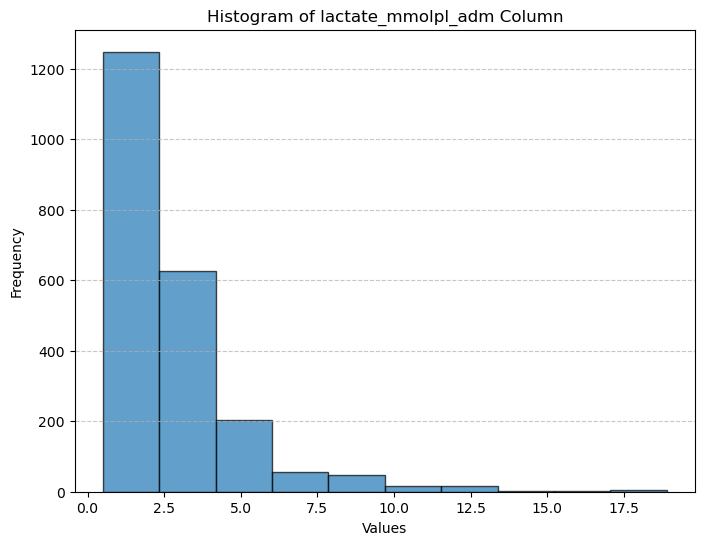

In [20]:
# Plotting the lactate2_mmolpl_adm column
plt.figure(figsize=(8, 6))
plt.hist(clean_data['lactate_mmolpl_adm'], bins=10, edgecolor='black', alpha=0.7)
plt.title('Histogram of lactate_mmolpl_adm Column')
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

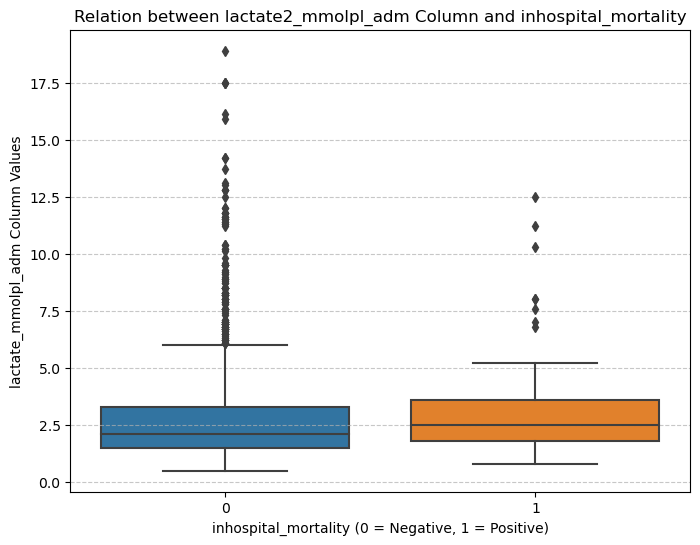

In [21]:
# Plotting the boxplot
plt.figure(figsize=(8, 6))
sns.boxplot(x='inhospital_mortality', y='lactate_mmolpl_adm', data=clean_data)
plt.title('Relation between lactate2_mmolpl_adm Column and inhospital_mortality')
plt.xlabel('inhospital_mortality (0 = Negative, 1 = Positive)')
plt.ylabel('lactate_mmolpl_adm Column Values')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Lactate level (mmol/L) Collected within 8hrs of admission**

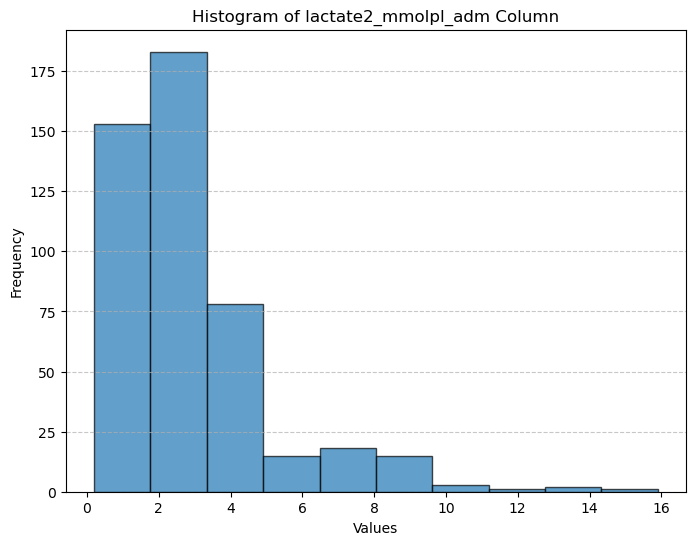

In [22]:
# Plotting the lactate2_mmolpl_adm column
plt.figure(figsize=(8, 6))
plt.hist(clean_data['lactate2_mmolpl_adm'], bins=10, edgecolor='black', alpha=0.7)
plt.title('Histogram of lactate2_mmolpl_adm Column')
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

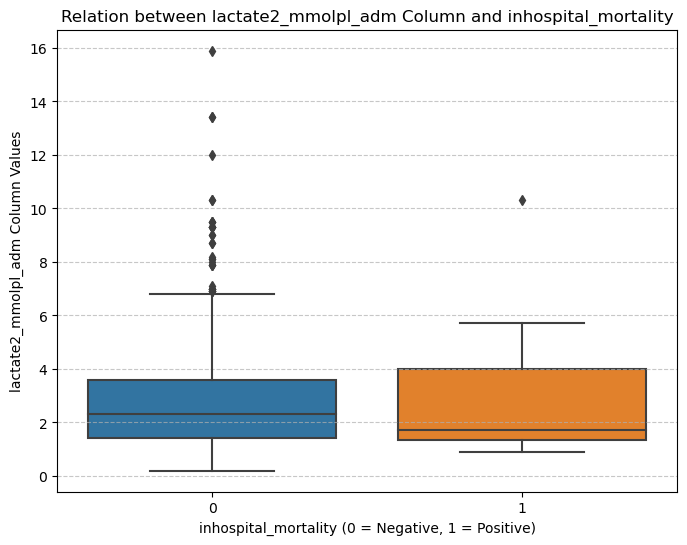

In [23]:
# Plotting the boxplot
plt.figure(figsize=(8, 6))
sns.boxplot(x='inhospital_mortality', y='lactate2_mmolpl_adm', data=clean_data)
plt.title('Relation between lactate2_mmolpl_adm Column and inhospital_mortality')
plt.xlabel('inhospital_mortality (0 = Negative, 1 = Positive)')
plt.ylabel('lactate2_mmolpl_adm Column Values')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In children Lactate is usually below 3 in normal conditions. Higher the value, worst the clinical condition of the patient. However, a big number of rows don't have the value, then statistical test or boxplot interpretation are not reliable.

**Hematocric admission**

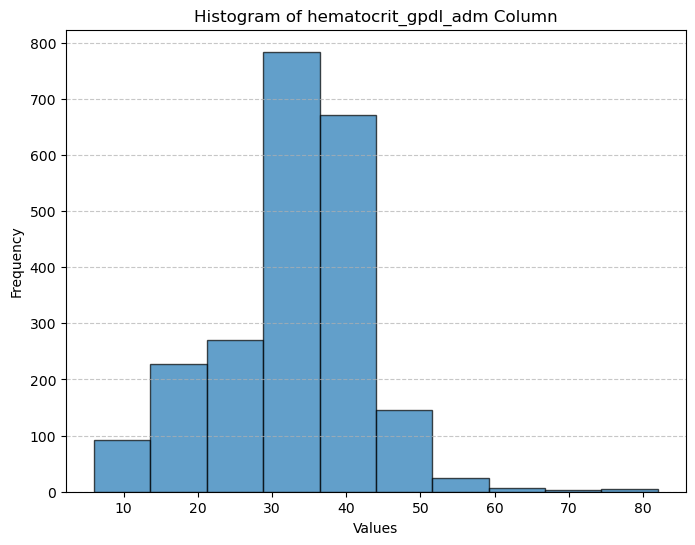

In [24]:
# Plotting the lactate2_mmolpl_adm column
plt.figure(figsize=(8, 6))
plt.hist(clean_data['hematocrit_gpdl_adm'], bins=10, edgecolor='black', alpha=0.7)
plt.title('Histogram of hematocrit_gpdl_adm Column')
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

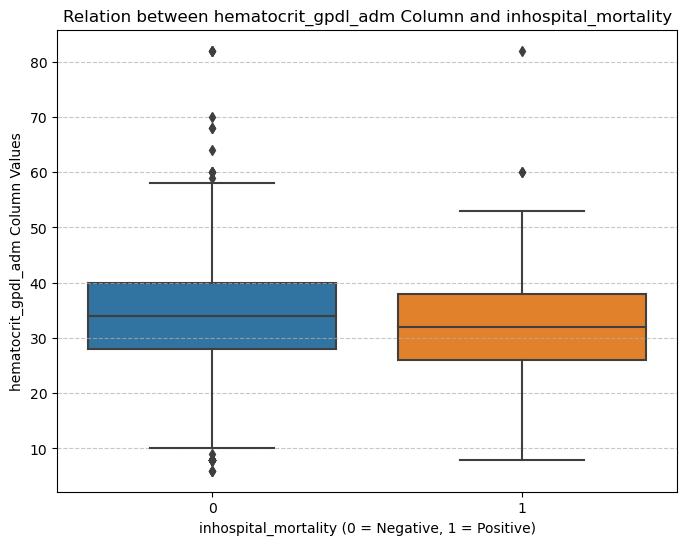

In [25]:
# Plotting the boxplot
plt.figure(figsize=(8, 6))
sns.boxplot(x='inhospital_mortality', y='hematocrit_gpdl_adm', data=clean_data)
plt.title('Relation between hematocrit_gpdl_adm Column and inhospital_mortality')
plt.xlabel('inhospital_mortality (0 = Negative, 1 = Positive)')
plt.ylabel('hematocrit_gpdl_adm Column Values')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Source of the information regarding measles vaccination?**

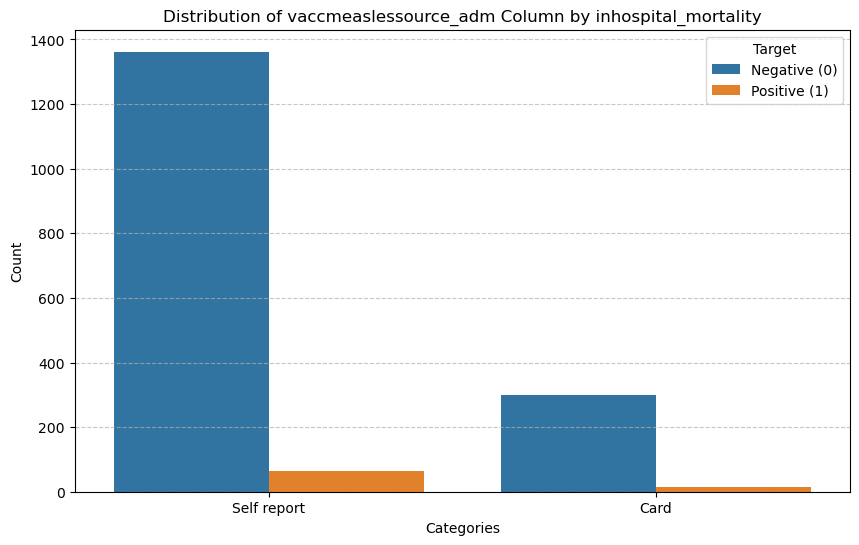

In [26]:
# Plot countplot
plt.figure(figsize=(10, 6))
sns.countplot(x='vaccmeaslessource_adm', hue='inhospital_mortality', data=clean_data)
plt.title('Distribution of vaccmeaslessource_adm Column by inhospital_mortality')
plt.xlabel('Categories')
plt.ylabel('Count')
plt.legend(title='Target', labels=['Negative (0)', 'Positive (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Let's drop 'lactate2_mmolpl_adm' and 'vaccmeaslessource_adm' columns.  

In [27]:
# Delete not relevant columns
clean_data.drop(columns = ['lactate2_mmolpl_adm', 'vaccmeaslessource_adm'], inplace=True)

In [28]:
#Sanity check
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Columns: 114 entries, agecalc_adm to inhospital_mortality
dtypes: float64(21), int64(1), object(92)
memory usage: 2.3+ MB


## Continue here

<div class="alert alert-block alert-info">
<b>TASK:</b> DEFINE WHAT TO DO WITH THE MISSING DATA.
</div>

If we drop the nan values the dataset reduces to 1453 rows, to bad the data loss to just drop.

In [42]:
# Getting the percentage of missing data in columns with missing values
missing_percentage = clean_data.isnull().sum() / len(df_with_missing) * 100
missing_percentage.sort_values(ascending=False)

lactate_mmolpl_adm      17.274758
hematocrit_gpdl_adm     17.014147
momagefirstpreg_adm      8.339538
sqi2_perc_oxi_adm        7.706627
spo2site2_pc_oxi_adm     7.632167
                          ...    
comorbidity_adm___1      0.000000
symptoms_adm___18        0.000000
symptoms_adm___17        0.000000
symptoms_adm___16        0.000000
inhospital_mortality     0.000000
Length: 114, dtype: float64

In [34]:
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2686 entries, 0 to 2685
Columns: 114 entries, agecalc_adm to inhospital_mortality
dtypes: float64(21), int64(1), object(92)
memory usage: 2.3+ MB


In [38]:
clean_data.dropna()

,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,spo2site1_pc_oxi_adm,...,cookloc_adm,lightfuel_adm,tobacco_adm,bednet_adm,hctpretransfusion_adm,hivstatus_adm,malariastatuspos_adm,lengthadm,caregiver_adm_new,inhospital_mortality
0,16.8,79.8,11.6,150.0,130.0,23.0,92.0,54.0,36.3,99.0,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,No,2,Mother,0
1,46.1,93.0,13.6,151.0,115.0,35.0,72.0,42.0,36.8,92.0,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,Yes,5,Mother,0
2,7.9,68.2,8.2,148.0,150.0,56.0,94.0,51.0,37.2,99.0,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,No,4,Mother,0
4,16.1,83.0,12.0,165.0,163.0,61.0,107.0,73.0,38.7,90.0,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,Yes,HIV negative,Yes,7,Mother,0
11,9.1,70.0,8.7,150.0,168.0,44.0,88.0,57.0,38.1,98.0,...,In a separate building/building space used as ...,Solar lantern,Never,Always,Yes,HIV negative,Yes,4,Mother,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2679,9.3,65.0,7.0,158.0,139.0,40.0,100.0,56.0,39.1,93.0,...,In the house where you sleep,Electric bulbs (national grid),Never,Always,Yes,HIV negative,No,11,Mother,0
2680,7.7,73.3,9.0,130.0,174.0,73.0,103.0,69.0,36.5,94.0,...,Outdoors in the open,Tadooba,Never,Always,No,HIV negative,No,3,Mother,0
2681,20.1,98.2,10.0,135.0,163.0,61.0,103.0,54.0,39.6,98.0,...,Outdoors in the open,Solar powered bulbs,Never,Always,Yes,HIV negative,No,3,Mother,0
2684,9.5,67.5,7.5,130.0,145.0,26.0,88.0,52.0,37.3,99.0,...,In a separate building/building space used as ...,Solar powered bulbs,Never,Always,Yes,HIV negative,No,4,Mother,0


### Data Exploration

#### Numerical columns

In [29]:
# Let's check the numerical columns
clean_data.select_dtypes("number").columns

Index(['agecalc_adm', 'height_cm_adm', 'weight_kg_adm', 'muac_mm_adm',
       'hr_bpm_adm', 'rr_brpm_app_adm', 'sysbp_mmhg_adm', 'diasbp_mmhg_adm',
       'temp_c_adm', 'spo2site1_pc_oxi_adm', 'spo2site2_pc_oxi_adm',
       'momage_adm', 'momagefirstpreg_adm', 'householdsize_adm',
       'alivechildren_adm', 'deadchildren_adm', 'hematocrit_gpdl_adm',
       'lactate_mmolpl_adm', 'glucose_mmolpl_adm', 'sqi1_perc_oxi_adm',
       'sqi2_perc_oxi_adm', 'lengthadm'],
      dtype='object')

In [30]:
# Statistical summary for the numerical columns
clean_data.describe()

,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,spo2site1_pc_oxi_adm,...,momagefirstpreg_adm,householdsize_adm,alivechildren_adm,deadchildren_adm,hematocrit_gpdl_adm,lactate_mmolpl_adm,glucose_mmolpl_adm,sqi1_perc_oxi_adm,sqi2_perc_oxi_adm,lengthadm
count,2686.00000,2672.000000,2677.000000,2673.000000,2685.000000,2681.000000,2684.000000,2685.000000,2685.000000,2682.000000,...,2462.000000,2683.000000,2682.00000,2685.000000,2229.000000,2222.000000,2677.000000,2556.000000,2479.000000,2686.000000
mean,21.12338,79.659401,9.577265,138.076693,141.219367,46.179784,96.941133,54.594041,37.470503,94.750186,...,19.245329,5.142751,3.02349,0.354935,32.954240,2.774887,6.320882,88.780516,78.004841,5.377141
std,13.05725,11.110075,2.796121,15.934621,25.550612,14.871732,11.876974,11.005274,1.007606,6.389585,...,3.386628,2.132131,1.81805,0.810868,9.750002,2.123403,2.512912,16.714758,23.383975,7.654527
min,5.90000,56.000000,2.610000,75.000000,42.000000,17.000000,58.000000,15.000000,33.600000,57.000000,...,12.000000,2.000000,0.00000,0.000000,6.000000,0.500000,0.000000,0.000000,0.000000,-85.000000
25%,10.52500,71.500000,7.640000,130.000000,128.000000,35.000000,89.000000,48.000000,36.700000,93.000000,...,17.000000,4.000000,2.00000,0.000000,28.000000,1.500000,5.000000,87.000000,68.000000,3.000000
50%,16.90000,78.000000,9.000000,140.000000,143.000000,44.000000,96.000000,54.000000,37.200000,97.000000,...,19.000000,5.000000,3.00000,0.000000,34.000000,2.100000,6.000000,96.000000,87.000000,4.000000
75%,28.67500,86.700000,11.000000,149.000000,158.000000,56.000000,104.000000,62.000000,38.200000,99.000000,...,21.000000,6.000000,4.00000,0.000000,40.000000,3.300000,7.200000,99.000000,96.000000,6.000000
max,61.80000,122.000000,22.000000,190.000000,214.000000,116.000000,159.000000,103.000000,40.600000,100.000000,...,36.000000,19.000000,11.00000,9.000000,82.000000,18.900000,24.200000,99.000000,99.000000,210.000000


##### Visualize the distributions

#### Visualize the categorical Columns

<div class="alert alert-block alert-info">
<b>NOTE:</b> Compare the distributions and categories in both outcome classes. 
</div>

#### The outcome

In [31]:
clean_data['inhospital_mortality'].value_counts(normalize=True)

0    0.955696
1    0.044304
Name: inhospital_mortality, dtype: float64

### **New dataset: Intervention columns removed, outcome 'inhospital_mortality' datatype fixed, and 'studyid_adm' removed. Pending deal with missing data**

In [32]:
# Save the dataset
# clean_data.to_csv('clean_dataset.csv', index=False)